# Qwen3-30B-A3B: TorchAO + TransformerLens + sim-pruning

Separate experiment using the **actual LocalPruning / TorchPruningGroupMapper / PruningInstrumentor path**, not hand-written masks.

Same training setup as the TorchAO baseline: GPU 2, FP16 compute, FP32 LoRA on layers 45–47, rank 16, AdamW, batch 8 × 512, 100 steps; official WikiText train/validation splits packed separately, fixed validation subset. Only LoRA weights train. TL's added zero unembedding bias is explicitly frozen; adapter parameter identities are checked against the optimizer.

Sim-pruning: request **30% attention head dimensions and 30% MLP intermediate channels** in layers 45–47, all 128 experts per layer. Attention RoPE pairs and GQA mappings come from our group builder. Rounded realized ratios may differ slightly from 30%. rescale=False, existing dynamic RMSNorm correction enabled. No structural setup or group.prune() is executed: packed weights and shapes remain intact.

TL uses our Qwen3MoeWithExpertBridges adapter. TorchAO INT4 is registered as a graph-only Linear with TP. All experts are traced, including those not routed by the probe. The graph is released before training. Capture/audit hooks are removed after checking masks.

The SFTTrainer calls the PEFT/HF model; TL has replaced its children in place, so this is the same instrumented model. The audit explicitly checks this execution path. Original training and no-pruning notebooks are preserved.

In [1]:
import os, sys, json
from pathlib import Path
os.environ["CUDA_VISIBLE_DEVICES"] = "2"
os.environ["COMPUTE_DTYPE"] = "fp16"
os.environ["HF_HUB_CACHE"] = "/glazkov-dev/.cache"
os.environ["HF_DATASETS_CACHE"] = "/glazkov-dev/.cache/datasets"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
root = Path.cwd()
while not (root / "lora_transfer_pruning").exists():
    if (root / "LoRa-Transfer-Pruning").exists():
        root = root / "LoRa-Transfer-Pruning"
        break
    if root == root.parent:
        raise RuntimeError("Cannot locate repository")
    root = root.parent
experiment_dir = root / "experiments/qlora"
sys.path.insert(0, str(root))
sys.path.insert(0, str(experiment_dir))
results_dir = experiment_dir / "slop_experiments/6_torchao_simpruning_train/torchao_sft_simpruning"


## Run or inspect

Default: read measured results, no GPU model allocation. RUN_TRAINING=True starts a fresh run. No checkpoints are saved.

Command:
`CUDA_VISIBLE_DEVICES=2 COMPUTE_DTYPE=fp16 .venv/bin/python -u experiments/qlora/torchao_exploration/train_qwen_torchao_simpruning.py`

LoRA layers/modules are configured in add_lora() in train_qwen_torchao.py. The pruning layers below must have adapters for this DG-root strategy.

In [2]:
RUN_TRAINING = False
PRUNE_LAYERS = [45, 46, 47]
ATTN_RATIO = MLP_RATIO = 0.30
PRUNING_SEED = 0
CONFIG = dict(steps=100, batch_size=8, context_length=512,
              train_blocks=1024, eval_blocks=32, eval_every=20,
              learning_rate=2e-4, warmup_steps=5, seed=42)
if RUN_TRAINING:
    from experiments.qlora.torchao_exploration.train_qwen_torchao_sft import ExperimentConfig, run_experiment
    from experiments.qlora.torchao_exploration import train_qwen_torchao_simpruning as sp
    sp.LAYERS = PRUNE_LAYERS
    sp.ATTN_RATIO, sp.MLP_RATIO, sp.PRUNING_SEED = ATTN_RATIO, MLP_RATIO, PRUNING_SEED
    result = run_experiment(ExperimentConfig(**CONFIG), output=results_dir,
                            prepare_model=sp.prepare_simpruning)
else:
    result = json.loads((results_dir / "training.json").read_text())
display(result["setup"])


{'config': {'steps': 100,
  'batch_size': 8,
  'context_length': 512,
  'train_blocks': 1024,
  'eval_blocks': 32,
  'eval_every': 20,
  'learning_rate': 0.0002,
  'warmup_steps': 5,
  'seed': 42},
 'checkpoint': 'Qwen/Qwen3-30B-A3B-GPTQ-Int4',
 'revision': '9b534e4318b7ebc3c961a839f13eb18b1833f441',
 'backend': 'GPTQ INT4 repacked for TorchAO fused Triton forward + backward',
 'compute_dtype': 'torch.float16',
 'lora_parameter_dtype': 'torch.float32',
 'physical_gpu': '2',
 'gpu': 'NVIDIA A100-PCIE-40GB',
 'lora_layers': [45, 46, 47],
 'lora_rank': 16,
 'lora_alpha': 32,
 'optimizer': 'AdamW, weight_decay=.01, cosine scheduler',
 'pruning': {'enabled': True,
  'layers': [45, 46, 47],
  'attention_ratio_requested': 0.3,
  'mlp_ratio_requested': 0.3,
  'seed': 0,
  'rescale': False,
  'group_count': 387,
  'linear_boundary_count': 1164,
  'wrapped_unpruned_eval': {'eval_loss': 2.6461071968078613,
   'eval_model_preparation_time': 0.3723,
   'eval_runtime': 24.7219,
   'eval_samples_per_

## Separate wrapping, pruning and learning effects

All validation measurements use the same held-out tokens. No masks are removed for evaluation. “Before training” means the already pruned model, not the unpruned reference. Accuracy is next-token top-1; perplexity = exp(mean NLL). The existing dynamic RMSNorm correction remains approximate; this experiment measures SP training, not exact equivalence to structural pruning.

In [3]:
import pandas as pd
stages = [
    ("HF unpruned", result["unpruned_before"]),
    ("TL unpruned", result["setup"]["pruning"]["wrapped_unpruned_eval"]),
    ("SP before training", result["before"]),
    ("SP after training", result["after"]),
]
comparison = pd.DataFrame([r for _, r in stages], index=[name for name, _ in stages])
display(comparison[["step", "eval_loss", "eval_perplexity", "eval_mean_token_accuracy", "eval_entropy"]])
display(result["setup"]["pruning"]["mask_audit"])
display({k: result[k] for k in ["adapter_check", "finite_train_metrics", "skipped_updates",
    "steady_samples_per_second", "steady_tokens_per_second", "peak_allocated_GiB",
    "training_wall_seconds_including_eval"]})


,step,eval_loss,eval_perplexity,eval_mean_token_accuracy,eval_entropy
HF unpruned,0,2.645524,14.090830,0.501101,1.425654
TL unpruned,0,2.646107,14.099047,0.501773,1.424733
SP before training,0,2.756535,15.745185,0.486057,1.482171
SP after training,100,2.301014,9.984298,0.517918,2.238299


{'checked_root_hooks': 387,
 'max_removed_activation': 0.0,
 'hf_peft_probe_loss': 3.9960732460021973}

{'adapter_check': {'parameter_tensors': 2328,
  'changed_tensors': 2307,
  'max_abs_update': 0.011298920959234238},
 'finite_train_metrics': True,
 'skipped_updates': 0,
 'steady_samples_per_second': 0.8592313655091746,
 'steady_tokens_per_second': 439.9264591406974,
 'peak_allocated_GiB': 27.835827350616455,
 'training_wall_seconds_including_eval': 1050.5052521266043}

WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.

INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.          

INFO:datasets:PyTorch version 2.10.0+cu128 available.


INFO  

┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐
│ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │
└─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘
GPT-QModel   : 7.0.0+7b8f06e
Transformers : 5.9.0
Torch        : 2.10.0+cu128
Triton       : 3.6.0

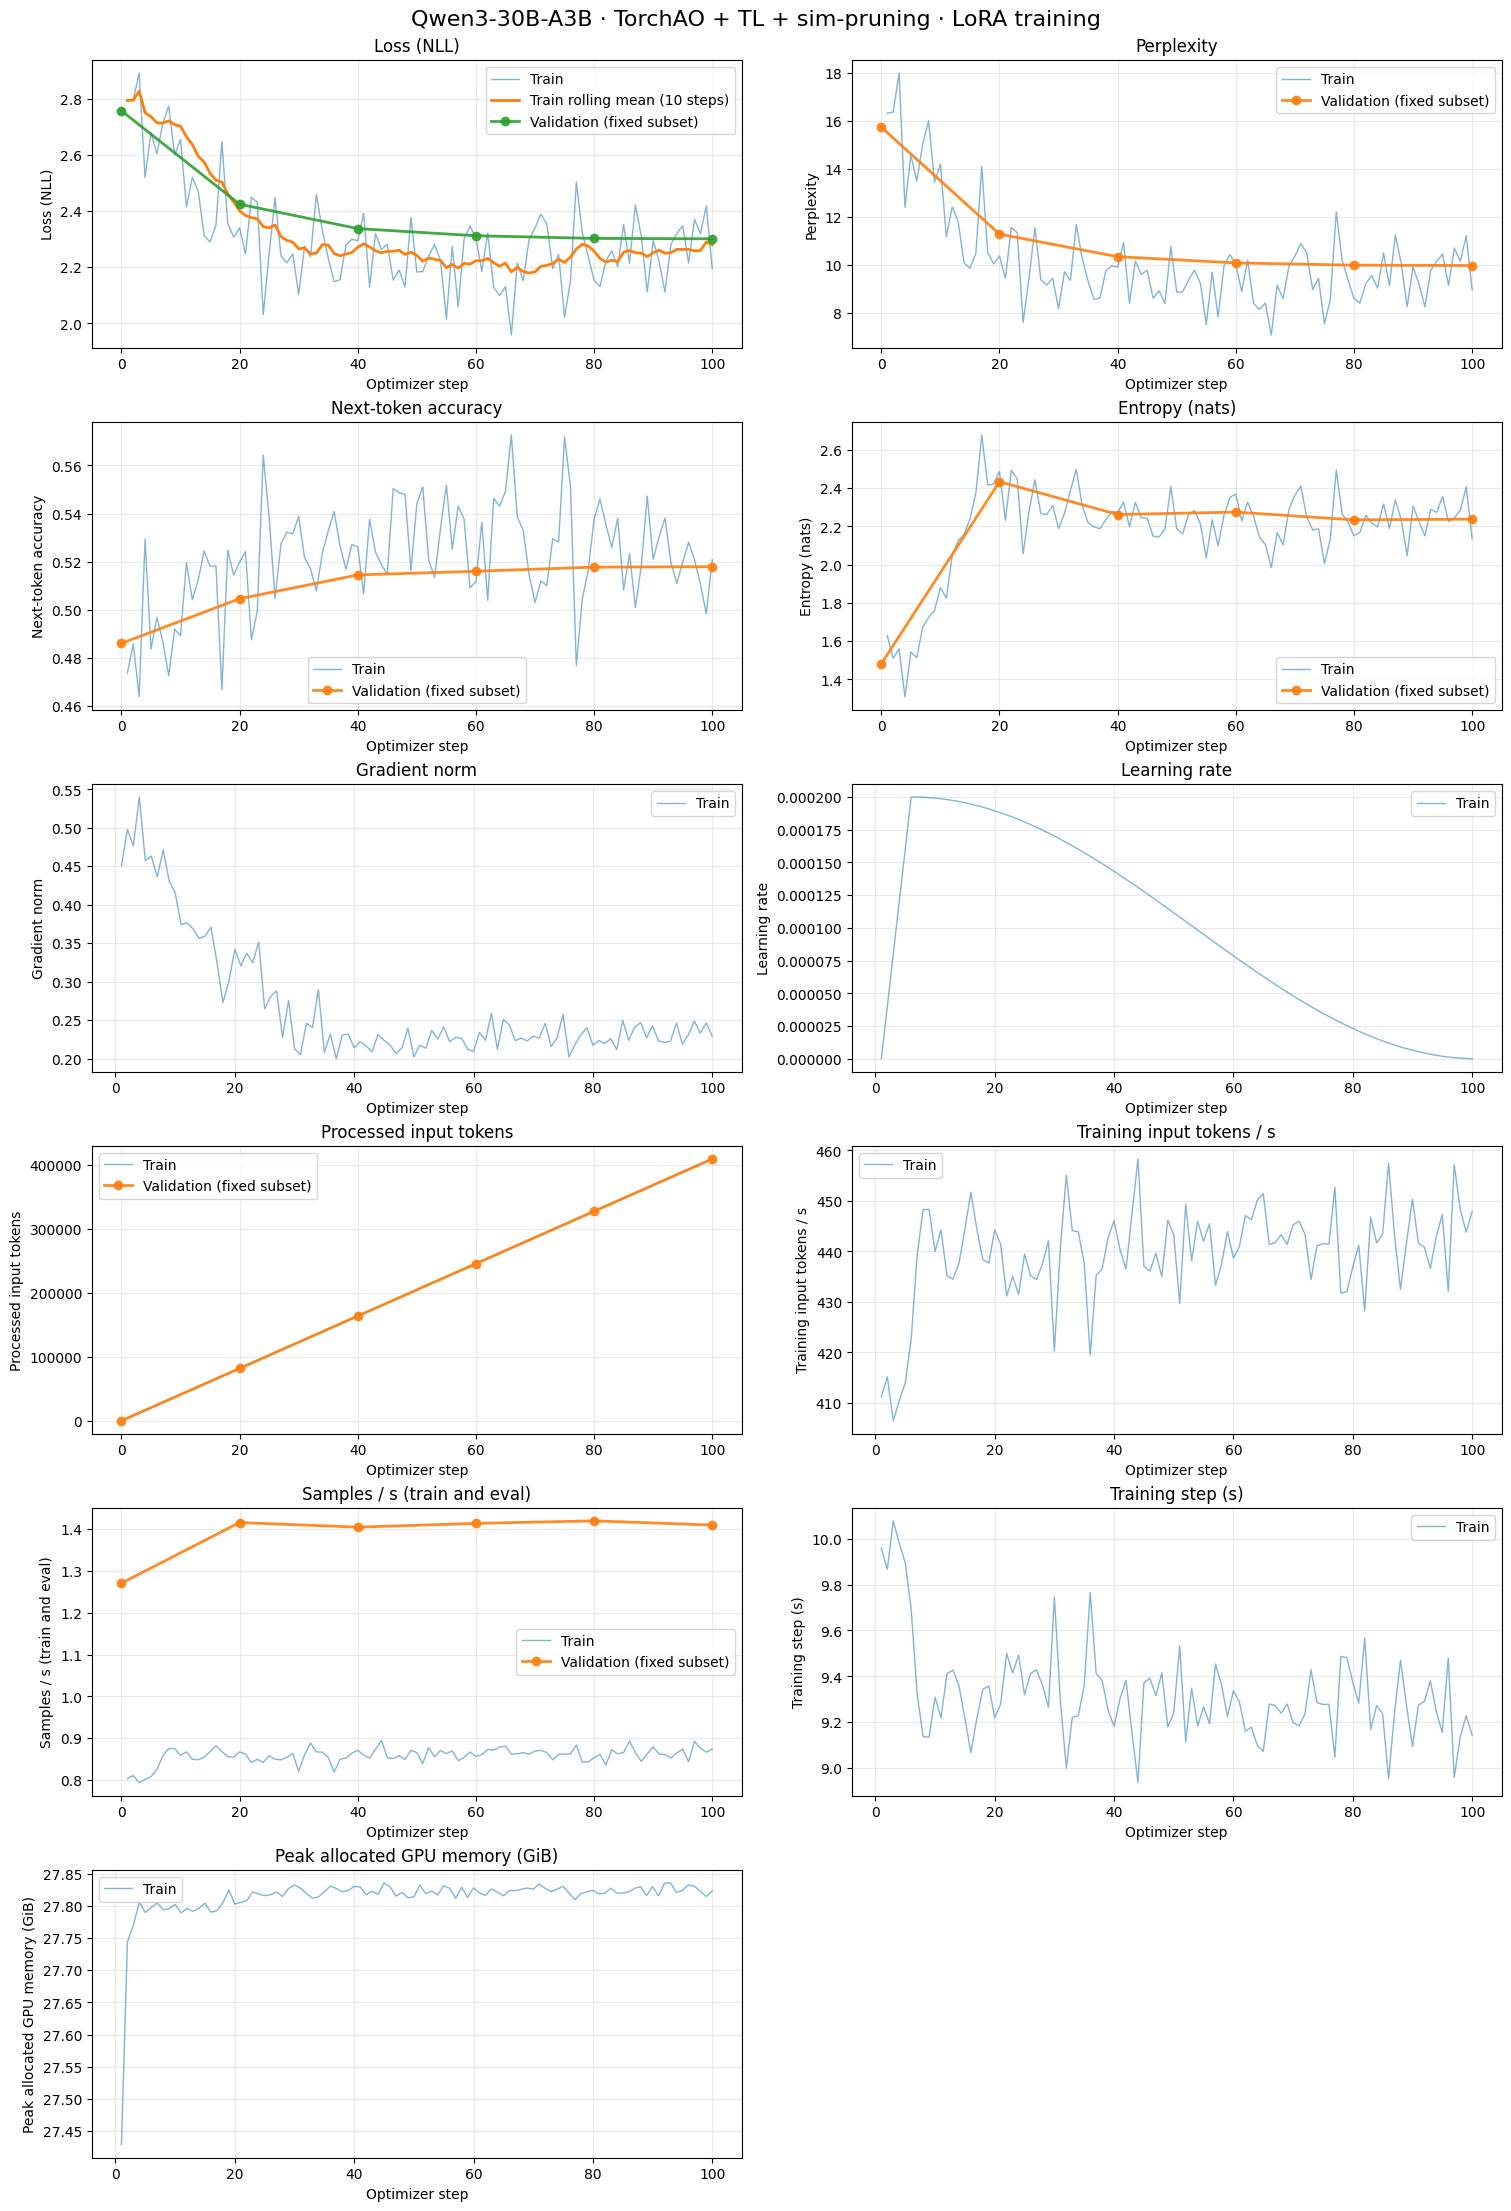

In [4]:
from experiments.qlora.torchao_exploration.train_qwen_torchao_sft import plot_training_history
import matplotlib.pyplot as plt
fig = plot_training_history(result["history"])
fig.suptitle("Qwen3-30B-A3B · TorchAO + TL + sim-pruning · LoRA training", fontsize=16)
fig.savefig(results_dir / "training_history.png", dpi=130)
plt.show()


## Previous no-pruning run versus sim-pruning

Same optimizer, LoRA initialization seed, data seed and fixed subsets. TL wrapping itself can change attention execution and adds overhead; its unpruned validation measurement above isolates numerical effects. Throughput excludes periodic validation and graph construction. These are separate runs on a shared host, not an interleaved microbenchmark.

In [5]:
baseline = json.loads((experiment_dir / "slop_experiments/4_torchao_train/torchao_sft/training.json").read_text())
rows = []
for name, run in [("TorchAO + LoRA (no TL/SP)", baseline), ("TorchAO + TL + SP + LoRA", result)]:
    rows.append(dict(run=name, loss_before=run["before"]["eval_loss"],
        loss_after=run["after"]["eval_loss"], perplexity_after=run["after"]["eval_perplexity"],
        accuracy_after=run["after"]["eval_mean_token_accuracy"],
        tokens_per_second=run["steady_tokens_per_second"],
        samples_per_second=run["steady_samples_per_second"],
        batches_per_second=run["steady_samples_per_second"] / run["setup"]["config"]["batch_size"],
        peak_GiB=run["peak_allocated_GiB"]))
display(pd.DataFrame(rows))
history = pd.DataFrame(result["history"])
display(history[history.eval_loss.notna()].dropna(axis=1, how="all"))
history.to_csv(results_dir / "history.csv", index=False)
plan = json.loads((results_dir / "pruning_plan.json").read_text())
display(pd.DataFrame([{"hook": r["hook"], "removed_channels": len(r["removed_indices"])}
                      for r in plan]).head(30))
print("All exact indices:", results_dir / "pruning_plan.json")


,run,loss_before,loss_after,perplexity_after,accuracy_after,tokens_per_second,samples_per_second,batches_per_second,peak_GiB
0,TorchAO + LoRA (no TL/SP),2.645524,2.213586,9.148463,0.527214,732.134612,1.429950,0.178744,26.645975
1,TorchAO + TL + SP + LoRA,2.756535,2.301014,9.984298,0.517918,439.926459,0.859231,0.107404,27.835827


,eval_loss,eval_model_preparation_time,eval_runtime,eval_samples_per_second,eval_steps_per_second,eval_entropy,eval_num_tokens,eval_mean_token_accuracy,epoch,step,eval_perplexity
0,2.756535,0.3723,25.1776,1.271,0.159,1.482171,0.0,0.486057,0.00000,0,15.745185
21,2.424111,0.3723,22.6056,1.416,0.177,2.434220,81920.0,0.504587,0.15625,20,11.292190
42,2.337409,0.3723,22.7704,1.405,0.176,2.262682,163840.0,0.514494,0.31250,40,10.354369
63,2.311947,0.3723,22.6283,1.414,0.177,2.275155,245760.0,0.516022,0.46875,60,10.094057
84,2.302538,0.3723,22.5414,1.420,0.177,2.234806,327680.0,0.517735,0.62500,80,9.999526
105,2.301014,0.3723,22.7020,1.410,0.176,2.238299,409600.0,0.517918,0.78125,100,9.984298


,hook,removed_channels
0,blocks.45.attn.q.hook_out,1216
1,blocks.45.attn.o.hook_in,1216
2,blocks.45.attn.v.hook_out,152
3,blocks.45.attn.k.hook_out,152
4,blocks.46.attn.q.hook_out,1216
5,blocks.46.attn.o.hook_in,1216
6,blocks.46.attn.v.hook_out,152
7,blocks.46.attn.k.hook_out,152
8,blocks.47.attn.q.hook_out,1216
9,blocks.47.attn.o.hook_in,1216


All exact indices: /glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/6_torchao_simpruning/torchao_sft_simpruning/pruning_plan.json
